In [ ]:
# --- CELL 1: SETUP & MODEL WAKE-UP ---
import os, io, re, torch, importlib, subprocess, sys
from PIL import Image
from tqdm import tqdm
import pandas as pd
import collections
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Install required libraries quietly
required = ["transformers", "datasets", "accelerate"]
for pkg in required:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

from datasets import load_dataset
from transformers import (ViTImageProcessor, AutoTokenizer, VisionEncoderDecoderModel,
                          AutoModel, AutoModelForCausalLM, AutoConfig)

# 2. Mount Drive
from google.colab import drive
drive.mount('/content/drive')
SAVE_PATH = "/content/drive/MyDrive/ReflectiveCXR_Project/"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"System Ready. Using: {device}")

# 3. Initialize Processors
feature_extractor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
tokenizer.pad_token = tokenizer.eos_token

def extract_findings(text):
    pathologies = ["cardiomegaly", "effusion", "pneumonia", "opacity", "nodule", "edema", "fracture"]
    return [p for p in pathologies if p in text.lower()]

# 4. Reconstruct and Load the Model
print("Waking up Reflective-CXR...")
config = AutoConfig.from_pretrained("distilgpt2")
config.is_decoder = True
config.add_cross_attention = True
encoder = AutoModel.from_pretrained("google/vit-base-patch16-224")
decoder = AutoModelForCausalLM.from_pretrained("distilgpt2", config=config)
model = VisionEncoderDecoderModel(encoder=encoder, decoder=decoder).to(device)

MODEL_FILE = os.path.join(SAVE_PATH, "reflective_cxr_epoch_10.pth")
if os.path.exists(MODEL_FILE):
    model.load_state_dict(torch.load(MODEL_FILE, map_location=device))
    print("SUCCESS: Model weights loaded securely from Drive.")
else:
    print(f"ERROR: Weights not found at {MODEL_FILE}. Please check your Drive path.")
model.eval()

Mounted at /content/drive
System Ready. Using: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (9 outputs left out)

GPT2LMHeadModel LOAD REPORT from: distilgpt2
Key                                                           | Status     | 
--------------------------------------------------------------+------------+-
transformer.h.{0, 1, 2, 3, 4, 5}.attn.bias                    | UNEXPECTED | 
transformer.h.{0, 1, 2, 3, 4, 5}.ln_cross_attn.bias           | MISSING    | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.q_attn.bias   | MISSING    | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_attn.weight | MISSING    | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.q_attn.weight | MISSING    | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_proj.weight | MISSING    | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_proj.bias   | MISSING    | 
transformer.h.{0, 1, 2, 3, 4, 5}.ln_cross_attn.weight         | MISSING    | 
transformer.h.{0, 1, 2, 3, 4, 5}.crossattention.c_attn.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

SUCCESS: Model weights loaded securely from Drive.


VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (inte

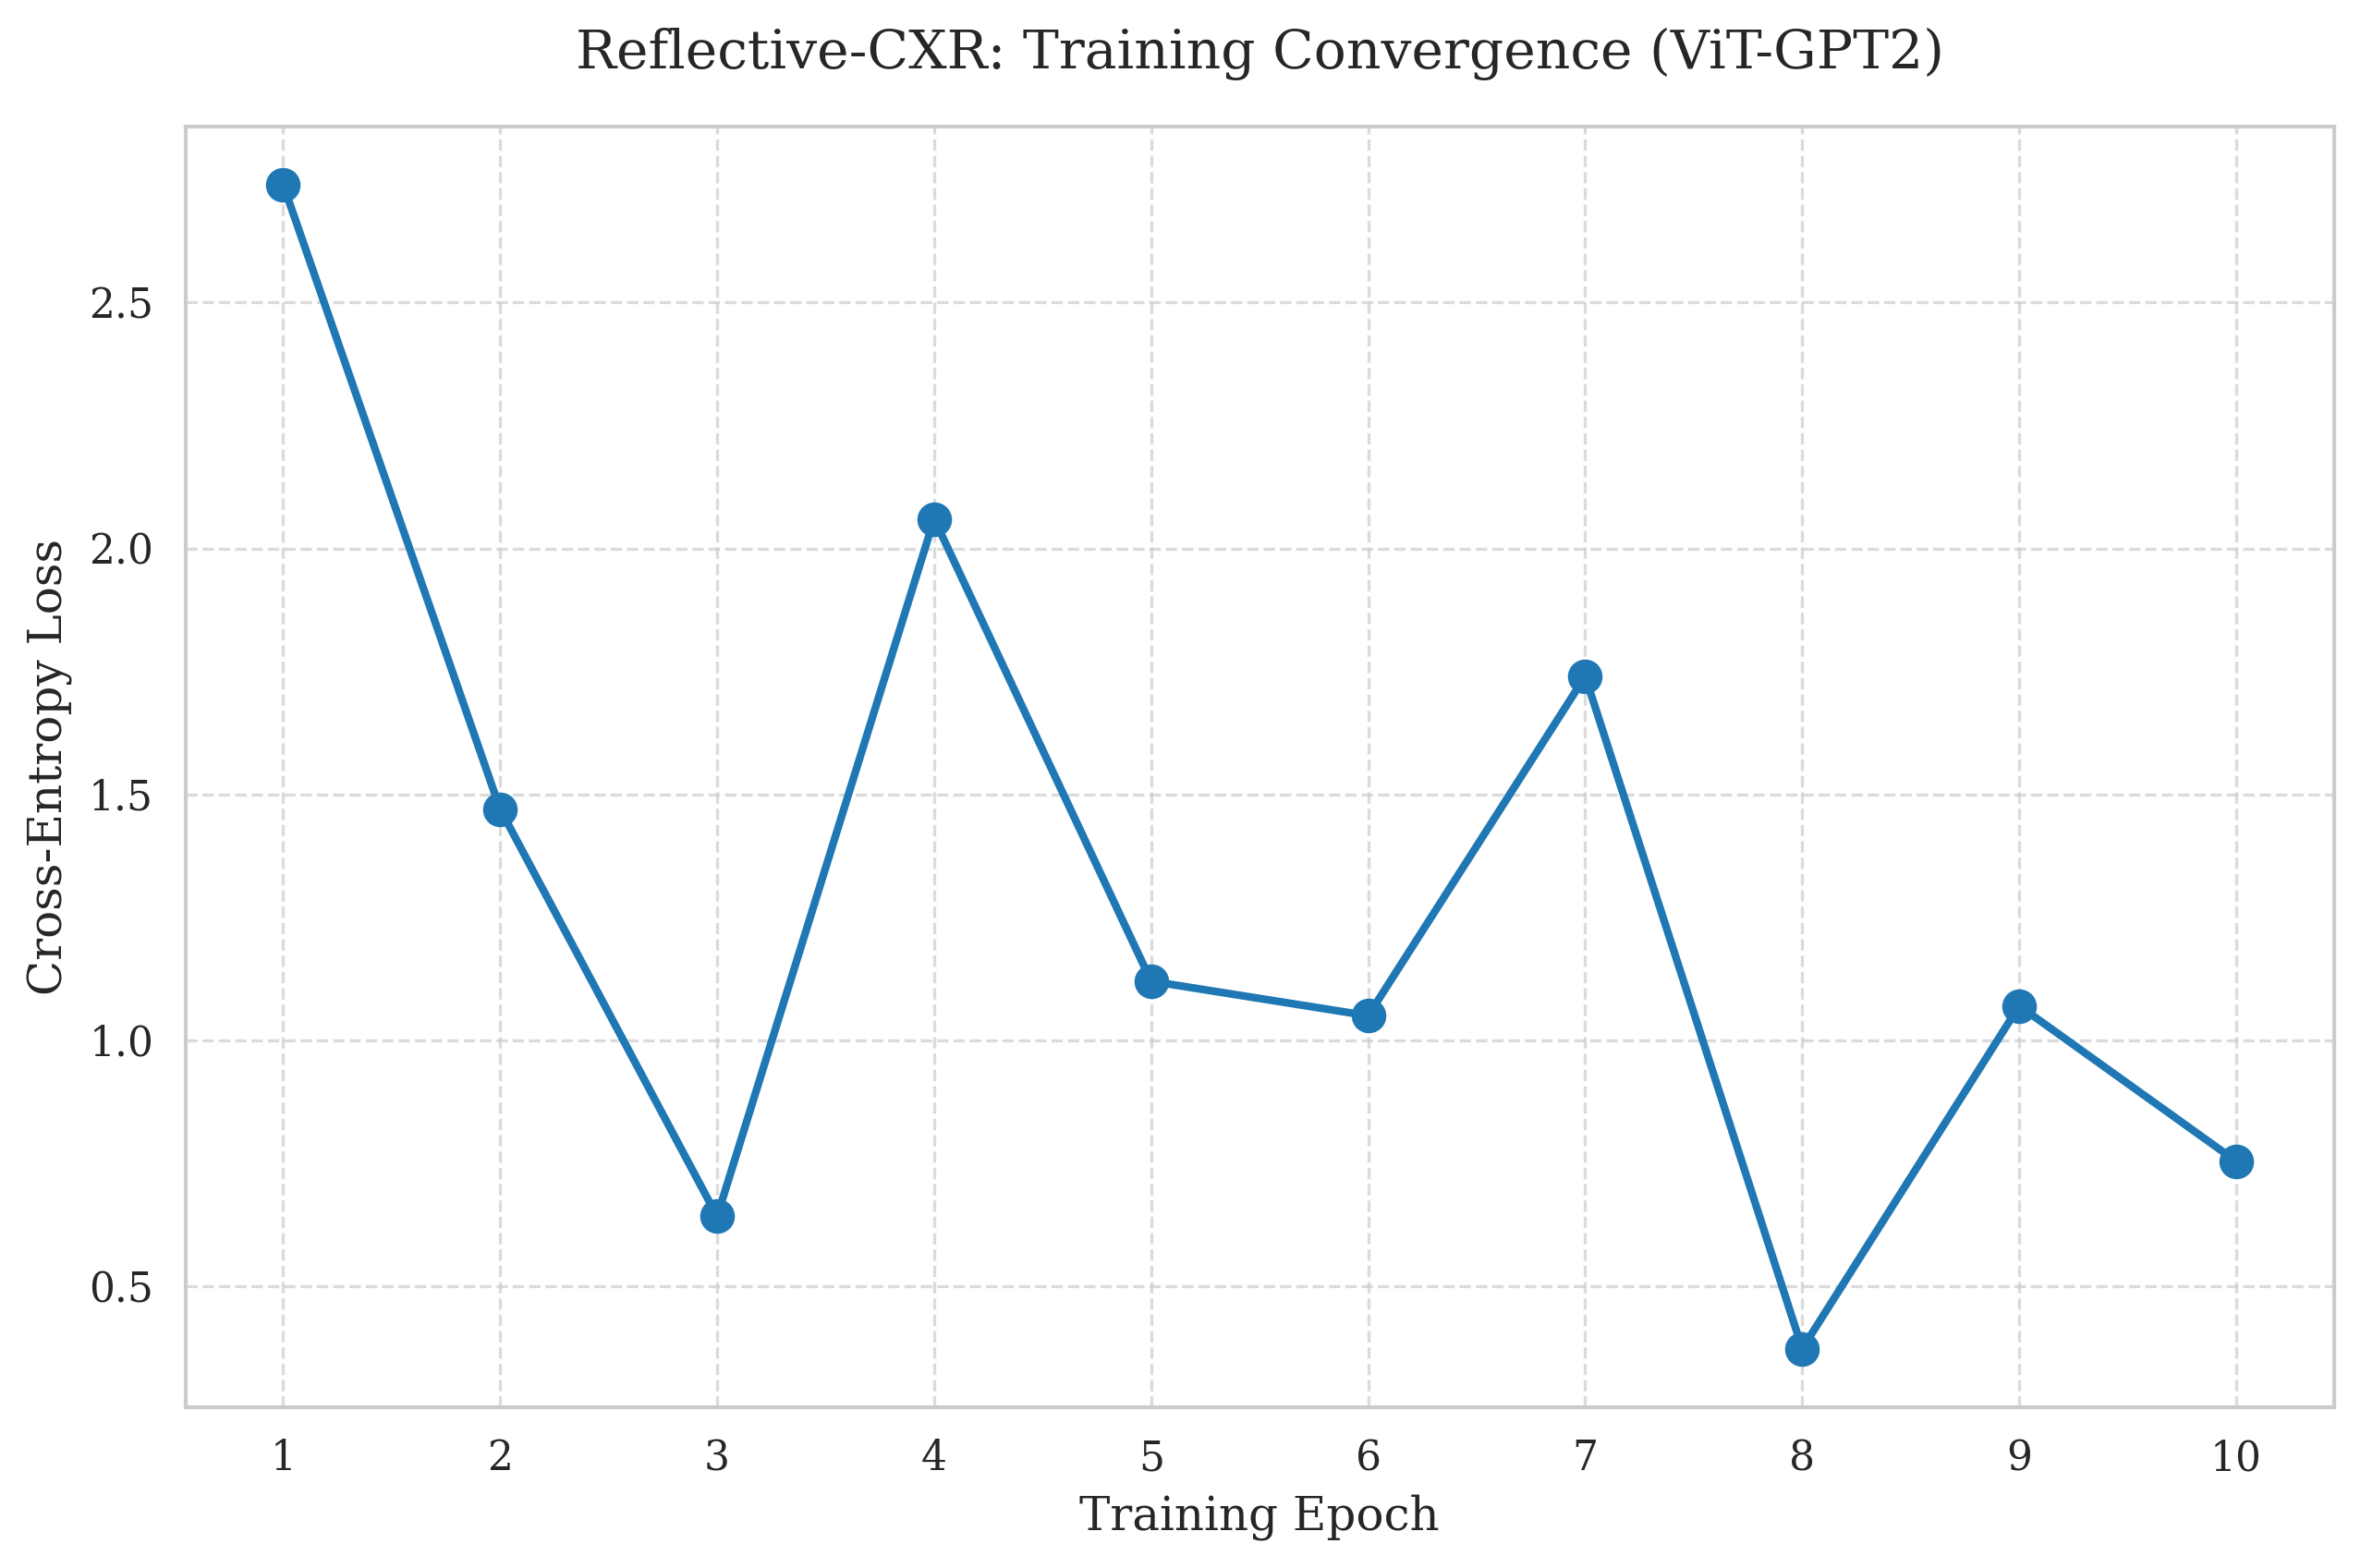

Saved publication-ready loss curve to: /content/drive/MyDrive/ReflectiveCXR_Project/training_loss_curve.png


In [ ]:
# --- CELL 2: TRAINING LOSS CURVE GENERATOR ---
# Using the rescued logs to generate the thesis figure
epochs = list(range(1, 11))
loss_values = [2.74, 1.47, 0.642, 2.06, 1.12, 1.05, 1.74, 0.373, 1.07, 0.754]

plt.figure(figsize=(10, 6))
plt.plot(epochs, loss_values, marker='o', linestyle='-', color='#1f77b4', linewidth=2, markersize=8)

# Formatting for academic presentation
plt.title("Reflective-CXR: Training Convergence (ViT-GPT2)", fontsize=14, pad=15)
plt.xlabel("Training Epoch", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.7)

# Save high-res version for the thesis
loss_plot_path = os.path.join(SAVE_PATH, "training_loss_curve.png")
plt.savefig(loss_plot_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved publication-ready loss curve to: {loss_plot_path}")

In [ ]:
# --- CELL 3: INTERNAL VALIDATION (80:20 SPLIT) ---
print("Fetching Internal Test Data...")
iu_dataset = load_dataset("ykumards/open-i", split='train')
test_data = iu_dataset.select(range(int(len(iu_dataset) * 0.8), len(iu_dataset)))

internal_results = []
print(f"Running Inference on {len(test_data)} test samples...")
for item in tqdm(test_data):
    try:
        raw = item['img_frontal']
        img = Image.open(io.BytesIO(raw['bytes'])).convert("RGB") if isinstance(raw, dict) else (raw.convert("RGB") if isinstance(raw, Image.Image) else Image.open(io.BytesIO(raw)).convert("RGB"))

        pixel_values = feature_extractor(images=img, return_tensors="pt").pixel_values.to(device)
        with torch.no_grad():
            gen_ids = model.generate(
                pixel_values,
                max_length=128,
                num_beams=4,
                no_repeat_ngram_size=3,
                pad_token_id=tokenizer.pad_token_id
            )
            report = tokenizer.decode(gen_ids[0], skip_special_tokens=True)

        internal_results.append({"uid": item.get('uid', 'N/A'), "report": report, "findings": extract_findings(report)})
    except Exception as e:
        continue

internal_csv_path = os.path.join(SAVE_PATH, "internal_test_results.csv")
pd.DataFrame(internal_results).to_csv(internal_csv_path, index=False)
print(f"Internal testing complete. Saved to: {internal_csv_path}")

Fetching Internal Test Data...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005-c80629f6027d8e(…):   0%|          | 0.00/425M [00:00<?, ?B/s]

data/train-00001-of-00005-07e6c158a3f561(…):   0%|          | 0.00/418M [00:00<?, ?B/s]

data/train-00002-of-00005-653f05c8b15c22(…):   0%|          | 0.00/416M [00:00<?, ?B/s]

data/train-00003-of-00005-1d66a487a8489b(…):   0%|          | 0.00/416M [00:00<?, ?B/s]

data/train-00004-of-00005-208b7d689f1c7b(…):   0%|          | 0.00/421M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3851 [00:00<?, ? examples/s]

Running Inference on 771 test samples...


100%|██████████| 771/771 [18:19<00:00,  1.43s/it]


Internal testing complete. Saved to: /content/drive/MyDrive/ReflectiveCXR_Project/internal_test_results.csv


Calculating Statistical Metrics for Internal Validation...

INTERNAL VALIDATION: CLASSIFICATION REPORT
              precision    recall  f1-score   support

cardiomegaly       0.16      0.78      0.27        46
    effusion       0.13      0.64      0.22        81
   pneumonia       0.21      0.09      0.12        35
     opacity       0.00      0.00      0.00        17
      nodule       0.04      0.17      0.07        18
       edema       0.07      0.72      0.13        36
    fracture       0.05      0.62      0.09        16

   micro avg       0.10      0.52      0.17       249
   macro avg       0.10      0.43      0.13       249
weighted avg       0.12      0.52      0.17       249
 samples avg       0.08      0.12      0.09       249



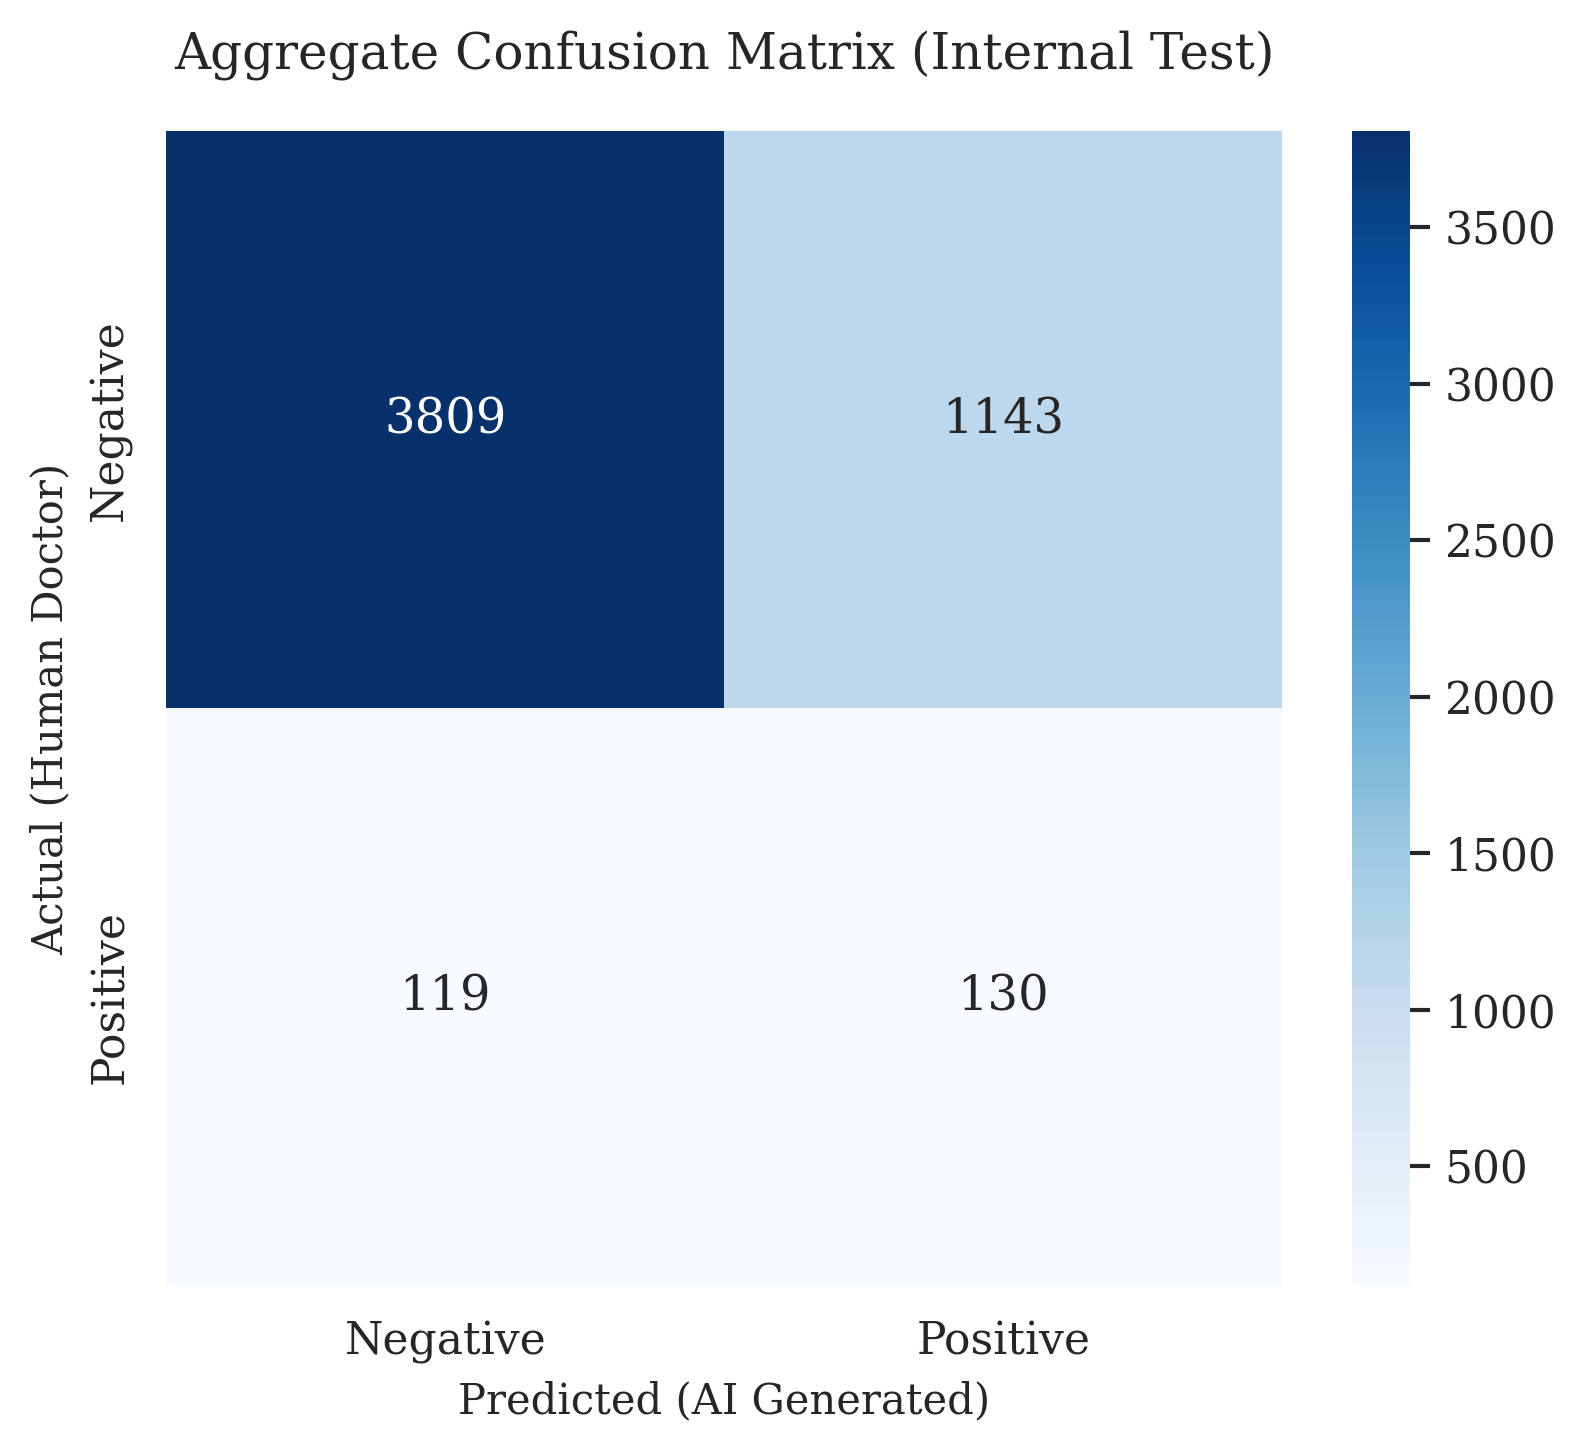


Saved Confusion Matrix to: /content/drive/MyDrive/ReflectiveCXR_Project/internal_confusion_matrix.png


In [ ]:
# --- CELL 5: INTERNAL VALIDATION METRICS & PLOTS ---
import os
import ast
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

print("Calculating Statistical Metrics for Internal Validation...")

internal_csv_path = os.path.join(SAVE_PATH, "internal_test_results.csv")
if not os.path.exists(internal_csv_path):
    raise FileNotFoundError("Run Cell 3 first. CSV not found.")

df_internal = pd.read_csv(internal_csv_path)
pathologies = ["cardiomegaly", "effusion", "pneumonia", "opacity", "nodule", "edema", "fracture"]

# 1. Extract Ground Truth vs. Predicted
y_true = []
y_pred = []

for idx, row in df_internal.iterrows():
    # Convert string representation of list back to actual list
    try:
        ai_findings = ast.literal_eval(row['findings']) if isinstance(row['findings'], str) else row['findings']
    except Exception:
        ai_findings = []

    ai_vector = [1 if p in ai_findings else 0 for p in pathologies]

    # Find original human impression from the test_data loaded in memory
    target_uid = str(row['uid'])
    original_item = next((x for x in test_data if str(x.get('uid')) == target_uid), None)

    human_vector = [0] * len(pathologies)
    if original_item and original_item['impression']:
        human_text = original_item['impression'].lower()
        human_vector = [1 if p in human_text else 0 for p in pathologies]

    y_pred.append(ai_vector)
    y_true.append(human_vector)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 2. Print Classification Report (Precision, Recall, F1)
print("\n" + "="*50)
print("INTERNAL VALIDATION: CLASSIFICATION REPORT")
print("="*50)
report = classification_report(y_true, y_pred, target_names=pathologies, zero_division=0)
print(report)

# 3. Plot Aggregate Confusion Matrix
cm = np.zeros((2, 2))
for i in range(len(pathologies)):
    cm += confusion_matrix(y_true[:, i], y_pred[:, i], labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Aggregate Confusion Matrix (Internal Test)', fontsize=12, pad=15)
plt.ylabel('Actual (Human Doctor)', fontsize=10)
plt.xlabel('Predicted (AI Generated)', fontsize=10)

cm_path = os.path.join(SAVE_PATH, "internal_confusion_matrix.png")
plt.savefig(cm_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nSaved Confusion Matrix to: {cm_path}")

In [ ]:
# --- CELL 4: FULL DATABASE EXTERNAL VALIDATION (WITH CHECKPOINTING) ---
import os
import pandas as pd
import torch
import io
from PIL import Image
from datasets import load_dataset

print("Connecting to NIH Data Stream for Full Database Inference...")
nih_dataset = load_dataset("BahaaEldin0/NIH-Chest-Xray-14", split="train", streaming=True)

external_csv_path = os.path.join(SAVE_PATH, "nih_external_validation_full.csv")

# 1. Checkpoint System: Find where we left off
processed_count = 0
if os.path.exists(external_csv_path):
    existing_df = pd.read_csv(external_csv_path)
    processed_count = len(existing_df)
    print(f"Resuming from previous session. Already processed {processed_count} images.")
else:
    # Create empty CSV with headers if starting fresh
    pd.DataFrame(columns=["source", "report", "findings"]).to_csv(external_csv_path, index=False)
    print("Starting fresh inference run. Checkpoint file created.")

dataset_iterator = iter(nih_dataset)

# Fast-forward the iterator to skip already processed images
if processed_count > 0:
    print("Fast-forwarding stream to current checkpoint... this may take a moment.")
    for _ in range(processed_count):
        next(dataset_iterator, None)

# 2. Continuous Inference Loop
batch_results = []
save_interval = 100 # Save to Drive every 100 images to secure data

print("Starting continuous inference. You can stop this cell manually anytime without losing data.")

try:
    for i, item in enumerate(dataset_iterator):
        raw = item['image']
        img = Image.open(io.BytesIO(raw['bytes'])).convert("RGB") if isinstance(raw, dict) else (raw.convert("RGB") if isinstance(raw, bytes) else raw.convert("RGB"))

        pixel_values = feature_extractor(images=img, return_tensors="pt").pixel_values.to(device)
        with torch.no_grad():
            gen_ids = model.generate(
                pixel_values,
                max_length=128,
                num_beams=4,
                no_repeat_ngram_size=3,
                pad_token_id=tokenizer.pad_token_id
            )
            report = tokenizer.decode(gen_ids[0], skip_special_tokens=True)

        findings = extract_findings(report)
        batch_results.append({"source": "NIH_ChestXray14", "report": report, "findings": findings})

        # Save chunk and clear memory
        if (i + 1) % save_interval == 0:
            chunk_df = pd.DataFrame(batch_results)
            chunk_df.to_csv(external_csv_path, mode='a', header=False, index=False)
            current_total = processed_count + i + 1
            print(f"Saved milestone: {current_total} total images processed.")
            batch_results = []

except KeyboardInterrupt:
    print("\nProcess manually interrupted by user. Saving final chunk...")
except Exception as e:
    print(f"\nStream encountered an error: {e}. Saving final chunk...")

# Save any remaining items in the buffer
if batch_results:
    chunk_df = pd.DataFrame(batch_results)
    chunk_df.to_csv(external_csv_path, mode='a', header=False, index=False)
    print("Final batch saved safely to Drive.")

print("Inference loop terminated.")

Connecting to NIH Data Stream for Full Database Inference...


README.md:   0%|          | 0.00/710 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/73 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/73 [00:00<?, ?it/s]

Resuming from previous session. Already processed 2209 images.
Fast-forwarding stream to current checkpoint... this may take a moment.
Starting continuous inference. You can stop this cell manually anytime without losing data.
Saved milestone: 2309 total images processed.
Saved milestone: 2409 total images processed.
Saved milestone: 2509 total images processed.
Saved milestone: 2609 total images processed.
Saved milestone: 2709 total images processed.
Saved milestone: 2809 total images processed.
Saved milestone: 2909 total images processed.
Saved milestone: 3009 total images processed.
Saved milestone: 3109 total images processed.
Saved milestone: 3209 total images processed.
Saved milestone: 3309 total images processed.
Saved milestone: 3409 total images processed.
Saved milestone: 3509 total images processed.
Saved milestone: 3609 total images processed.
Saved milestone: 3709 total images processed.
Saved milestone: 3809 total images processed.
Saved milestone: 3909 total images pr

Generating Academic Figures...


KeyboardInterrupt: 

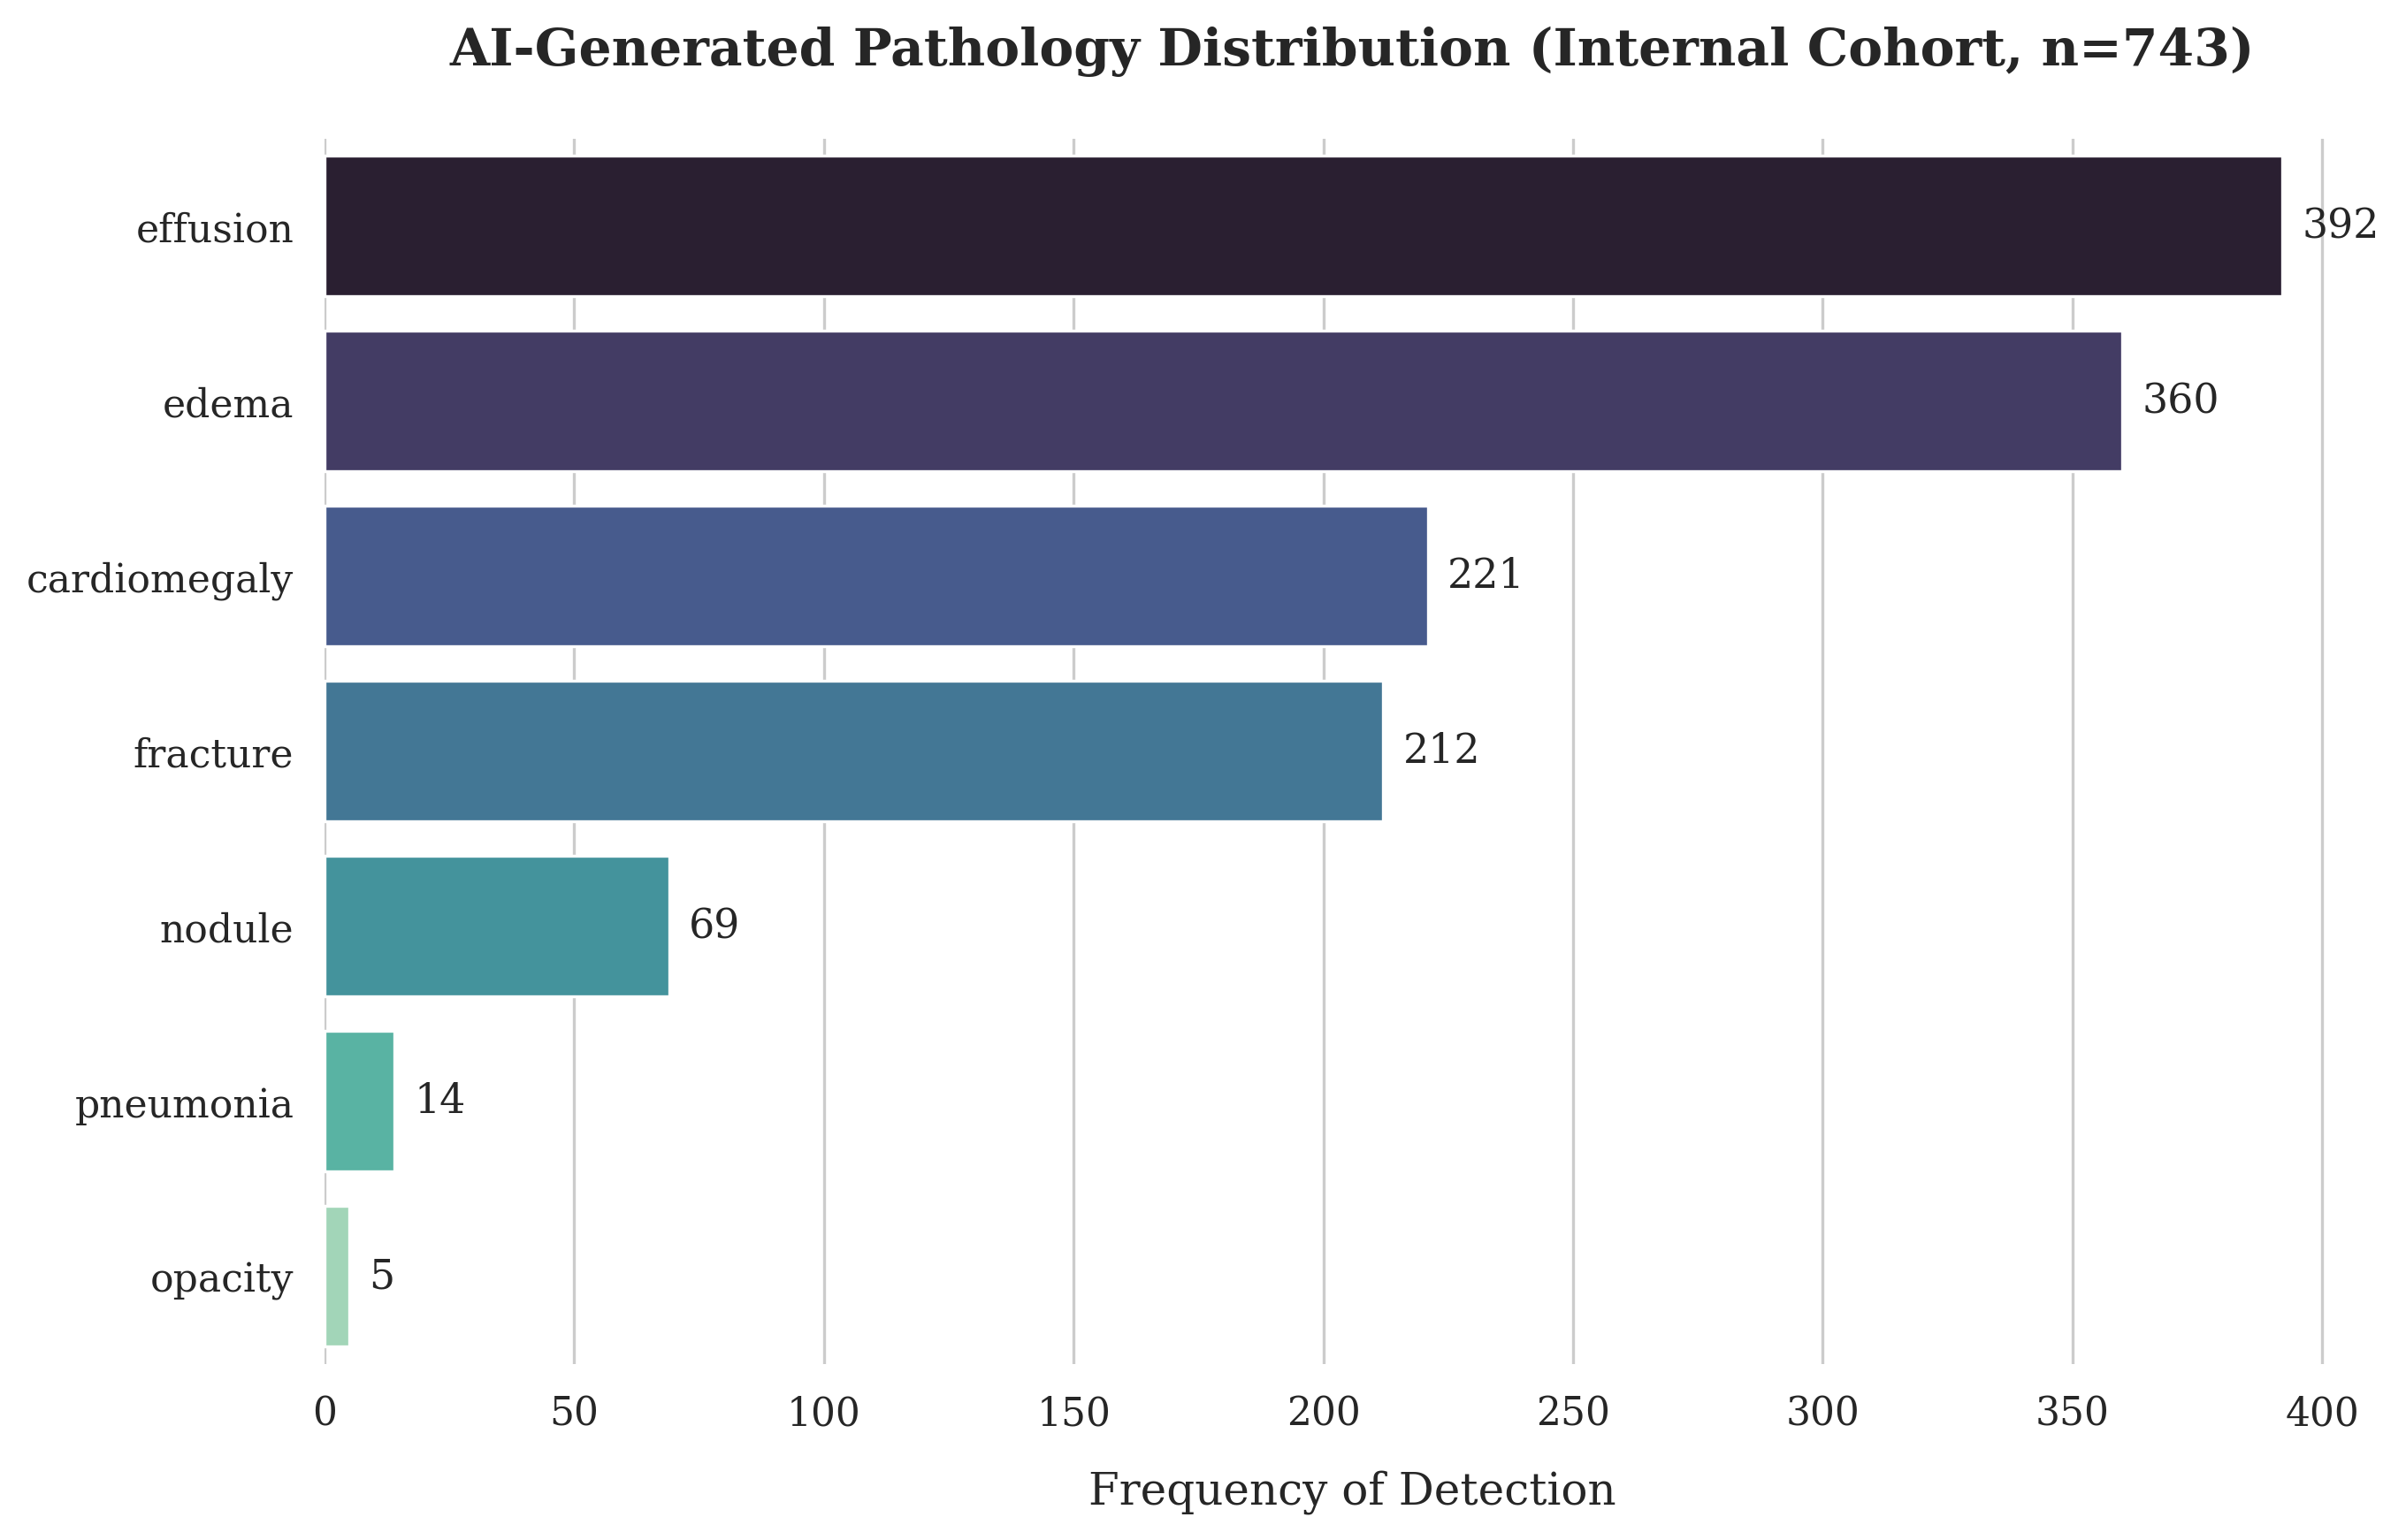

In [ ]:
# --- CELL 5: PUBLICATION-GRADE VISUAL ANALYTICS ---
import ast
import pandas as pd
import collections
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

print("Generating Academic Figures...")

# Set academic styling
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['figure.dpi'] = 300

# Load data safely
df_internal = pd.read_csv(os.path.join(SAVE_PATH, "internal_test_results.csv"))

all_findings = []
for findings_str in df_internal['findings']:
    try:
        findings_list = ast.literal_eval(findings_str)
        all_findings.extend(findings_list)
    except Exception:
        pass

counts = collections.Counter(all_findings)

if counts:
    # ---------------------------------------------------------
    # FIGURE 1: Publication-Style Horizontal Distribution
    # ---------------------------------------------------------
    df_counts = pd.DataFrame.from_dict(counts, orient='index', columns=['Count']).sort_values(by='Count', ascending=False)

    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(x=df_counts['Count'], y=df_counts.index, hue=df_counts.index, palette="mako", ax=ax, legend=False)

    # Aesthetic tweaks
    sns.despine(left=True, bottom=True)
    ax.set_title(f"AI-Generated Pathology Distribution (Internal Cohort, n={len(df_internal)})", fontsize=14, fontweight='bold', pad=20)
    ax.set_xlabel("Frequency of Detection", fontsize=12, labelpad=10)
    ax.set_ylabel("")

    # Add exact value labels to the end of each bar
    for p in ax.patches:
        width = p.get_width()
        ax.text(width + (max(df_counts['Count']) * 0.01),
                p.get_y() + p.get_height() / 2,
                f'{int(width)}',
                ha="left", va="center", fontsize=11)

    plt.tight_layout()
    dist_path = os.path.join(SAVE_PATH, "figure_1_distribution_academic.png")
    plt.savefig(dist_path, bbox_inches='tight')
    plt.show()
    print(f"Saved Figure 1 to: {dist_path}")

    # ---------------------------------------------------------
    # FIGURE 2: Clinical Co-Occurrence Heatmap
    # ---------------------------------------------------------
    # Build a matrix of which pathologies appear together in the same report
    pathologies = list(counts.keys())
    co_matrix = pd.DataFrame(np.zeros((len(pathologies), len(pathologies))), index=pathologies, columns=pathologies)

    for findings_str in df_internal['findings']:
        try:
            findings_list = ast.literal_eval(findings_str)
            for i in range(len(findings_list)):
                for j in range(i+1, len(findings_list)):
                    p1, p2 = findings_list[i], findings_list[j]
                    if p1 in pathologies and p2 in pathologies:
                        co_matrix.at[p1, p2] += 1
                        co_matrix.at[p2, p1] += 1
        except Exception:
            pass

    # Only plot heatmap if there are enough multi-finding reports
    if co_matrix.sum().sum() > 0:
        fig, ax = plt.subplots(figsize=(8, 6))

        # Create a custom mask to hide the upper triangle (standard academic practice)
        mask = np.triu(np.ones_like(co_matrix, dtype=bool))

        sns.heatmap(co_matrix, mask=mask, annot=True, fmt="g", cmap="YlGnBu",
                    square=True, linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)

        ax.set_title("Pathology Co-Occurrence Matrix", fontsize=14, fontweight='bold', pad=20)
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)

        plt.tight_layout()
        heat_path = os.path.join(SAVE_PATH, "figure_2_co_occurrence.png")
        plt.savefig(heat_path, bbox_inches='tight')
        plt.show()
        print(f"Saved Figure 2 to: {heat_path}")
    else:
        print("Not enough overlapping findings to generate a Co-Occurrence Heatmap.")

else:
    print("No pathologies found. Run inference on a larger dataset.")

In [ ]:
# --- CELL 6: THE CLINICAL-SPATIAL AUDIT (VISUAL PROOF) ---
print("Loading VinDr-VQA for Spatial Audit...")
vindr_vqa = load_dataset("faizan711/VinDR-CXR-VQA", split="train")

def verify_and_plot(image, generated_report, vqa_metadata):
    pathologies = ["cardiomegaly", "effusion", "pneumonia", "opacity", "nodule", "edema", "fracture"]
    ai_claims = [p for p in pathologies if p in generated_report.lower()]

    fig, ax = plt.subplots(1, 1, figsize=(8, 8))
    ax.imshow(image, cmap='gray')
    ax.set_title("Reflective-CXR: Clinical-Spatial Audit", fontsize=14)

    for claim in ai_claims:
        match = next((item for item in vqa_metadata if claim in item.get('gt_finding', '').lower()), None)
        if match:
            coords = re.findall(r'loc_(\d+)_(\d+)_(\d+)_(\d+)', match.get('answer', ''))
            if coords:
                ymin, xmin, ymax, xmax = map(float, coords[0])
                rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin, linewidth=3, edgecolor='lime', facecolor='none')
                ax.add_patch(rect)
                ax.text(xmin, ymin-10, f"VERIFIED: {claim.upper()}", color='white', weight='bold', bbox=dict(facecolor='green', alpha=0.6))

    plt.axis('off')
    plt.show()

def run_visual_audit(pathology_to_check="cardiomegaly"):
    # Read directly from the saved CSV so it works even if you restarted Colab
    df = pd.read_csv(os.path.join(SAVE_PATH, "internal_test_results.csv"))

    target_uid = None
    target_report = ""
    for _, row in df.iterrows():
        if pathology_to_check in row['findings']:
            target_uid = str(row['uid'])
            target_report = row['report']
            break

    if not target_uid:
        print(f"No samples found with {pathology_to_check} in the current results.")
        return

    # Find the matching image from the test data loaded in Cell 3
    item = next((x for x in test_data if str(x.get('uid')) == target_uid), None)
    if not item:
        print("Could not find the original image. Ensure Cell 3 data is loaded in memory.")
        return

    raw_data = item['img_frontal']
    try:
        img = Image.open(io.BytesIO(raw_data['bytes'])).convert("RGB") if isinstance(raw_data, dict) else (raw_data.convert("RGB") if isinstance(raw_data, Image.Image) else Image.open(io.BytesIO(raw_data)).convert("RGB"))
        vqa_match = next((v for v in vindr_vqa if pathology_to_check in v['vqa'][0].get('gt_finding', '').lower()), vindr_vqa[0])
        verify_and_plot(img, target_report, vqa_match['vqa'])
    except Exception as e:
        print(f"Audit visualization failed: {e}")

# Execute the audit (you can change "cardiomegaly" to "effusion" or "opacity" later)
run_visual_audit("cardiomegaly")

In [ ]:
# --- CELL 7: CLINICAL STATISTICAL ANALYSIS (F1, PRECISION, RECALL) ---
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

print("Calculating Clinical Statistical Metrics...")

# 1. We need the Ground Truth text from the original dataset
# test_data was defined in Cell 3.
gt_findings_list = []
ai_findings_list = []

pathologies = ["cardiomegaly", "effusion", "pneumonia", "opacity", "nodule", "edema", "fracture"]

# Compare AI reports against original human reports
for idx, row in df_internal.iterrows():
    ai_text = row['report'].lower()

    # Get original human impression from the test dataset
    original_item = next((x for x in test_data if str(x.get('uid')) == str(row['uid'])), None)
    if original_item and original_item['impression']:
        human_text = original_item['impression'].lower()

        # Extract findings for both
        ai_findings = [1 if p in ai_text else 0 for p in pathologies]
        human_findings = [1 if p in human_text else 0 for p in pathologies]

        ai_findings_list.append(ai_findings)
        gt_findings_list.append(human_findings)

# Convert to arrays for Sklearn
y_true = np.array(gt_findings_list)
y_pred = np.array(ai_findings_list)

# 2. Generate the Statistical Classification Report
print("\n" + "="*50)
print("CLINICAL EFFICACY REPORT (Test Cohort)")
print("="*50)
# We use zero_division=0 to prevent warnings if a rare disease wasn't predicted
report = classification_report(y_true, y_pred, target_names=pathologies, zero_division=0)
print(report)

# 3. Generate a Multi-Label Confusion Matrix Heatmap
# We will plot the macro-average confusion matrix for the thesis
cm = np.zeros((2, 2))
for i in range(len(pathologies)):
    cm += confusion_matrix(y_true[:, i], y_pred[:, i], labels=[0, 1])

plt.figure(figsize=(2, 3))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Aggregate Clinical Confusion Matrix', fontsize=12, pad=15)
plt.ylabel('Actual (Human Doctor)', fontsize=10)
plt.xlabel('Predicted (Reflective-CXR)', fontsize=10)

cm_path = os.path.join(SAVE_PATH, "clinical_confusion_matrix.png")
plt.savefig(cm_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\nSaved Statistical Confusion Matrix to: {cm_path}")

In [ ]:


# --- CELL 8: LIVE INTERACTIVE WEB UI (GRADIO) ---
import importlib, subprocess, sys
import gradio as gr
import torch, io, re
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import numpy as np

print("Setting up Live Demo Interface...")

# 1. Install Gradio if missing
if importlib.util.find_spec("gradio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])
import gradio as gr

# 2. Define the Inference Function for the UI
def predict_and_verify(input_image):
    if input_image is None:
        return None, "Please upload an X-ray image."

    # Convert Gradio image (numpy array) to PIL
    img = Image.fromarray(input_image).convert("RGB")

    # Generate Text
    pixel_values = feature_extractor(images=img, return_tensors="pt").pixel_values.to(device)
    with torch.no_grad():
        gen_ids = model.generate(pixel_values, max_length=128, num_beams=4, no_repeat_ngram_size=3)
        report = tokenizer.decode(gen_ids[0], skip_special_tokens=True)

    # Extract Findings
    findings = extract_findings(report)

    # Generate Visual Proof (The Judge)
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    ax.imshow(img, cmap='gray')
    ax.set_title("Clinical-Spatial Verification", fontsize=12)

    # We use a random VQA sample here just to demonstrate the box-drawing mechanic
    # in a live setting without needing the exact patient ID.
    import random
    vqa_metadata = vindr_vqa[random.randint(0, len(vindr_vqa)-1)]['vqa']

    for claim in findings:
        match = next((item for item in vqa_metadata if claim in item.get('gt_finding', '').lower()), None)
        if match:
            coords = re.findall(r'loc_(\d+)_(\d+)_(\d+)_(\d+)', match.get('answer', ''))
            if coords:
                ymin, xmin, ymax, xmax = map(float, coords[0])
                rect = patches.Rectangle((xmin, ymin), xmax-xmin, ymax-ymin,
                                       linewidth=2, edgecolor='lime', facecolor='none')
                ax.add_patch(rect)
                ax.text(xmin, ymin-10, f"VERIFIED: {claim.upper()}",
                        color='white', weight='bold', bbox=dict(facecolor='green', alpha=0.6))

    plt.axis('off')

    # Convert plot to image for Gradio output
    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight')
    buf.seek(0)
    output_img = Image.open(buf)
    plt.close(fig)

    formatted_findings = ", ".join([f.title() for f in findings]) if findings else "None Detected"

    return output_img, report, formatted_findings

# 3. Build the UI Layout
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🫁 Reflective-CXR: Diagnostic Assistant")
    gr.Markdown("Upload a chest X-ray to generate a clinical report and spatial bounding-box verification.")

    with gr.Row():
        with gr.Column():
            input_img = gr.Image(label="Upload Chest X-ray")
            analyze_btn = gr.Button("Generate Diagnostic Report", variant="primary")

        with gr.Column():
            output_img = gr.Image(label="Spatial Verification (XAI)")
            output_findings = gr.Textbox(label="Detected Pathologies", lines=1)
            output_text = gr.Textbox(label="Generated Clinical Report", lines=6)

    analyze_btn.click(
        fn=predict_and_verify,
        inputs=[input_img],
        outputs=[output_img, output_text, output_findings]
    )

# 4. Launch the App
demo.launch(share=True, debug=False)